In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.datasets import mnist
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


In [ ]:
#loading the data
(X, y), (X_test, y_test) = mnist.load_data()

print("Original training data:", X.shape)
print("Original training labels:", y.shape)
print("Test data:", X_test.shape)
print("Test labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original training data: (60000, 28, 28)
Original training labels: (60000,)
Test data: (10000, 28, 28)
Test labels: (10000,)


In [ ]:
#diff didgit classes present in the dataset
print("Classes:", np.unique(y))
print("Number of classes:", len(np.unique(y)))

print("\nClass distribution:")
unique, counts = np.unique(y, return_counts=True)

for digit, count in zip(unique, counts):
    print(f"Digit {digit}: {count} images")

Classes: [0 1 2 3 4 5 6 7 8 9]
Number of classes: 10

Class distribution:
Digit 0: 5923 images
Digit 1: 6742 images
Digit 2: 5958 images
Digit 3: 6131 images
Digit 4: 5842 images
Digit 5: 5421 images
Digit 6: 5918 images
Digit 7: 6265 images
Digit 8: 5851 images
Digit 9: 5949 images


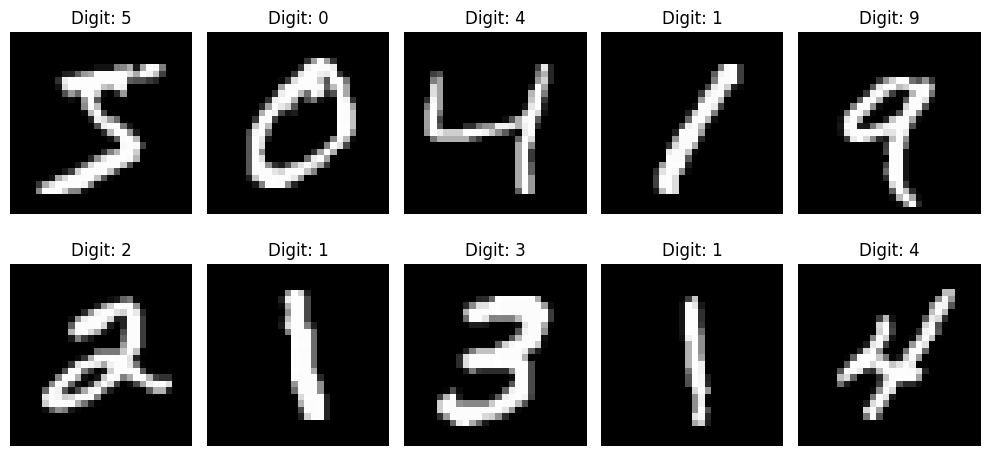

In [ ]:
#image sample
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i], cmap="gray")
    plt.title(f"Digit: {y[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#splitting data in training ,testing,validation
#10% frim training data is split for validation
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,y,
    test_size=0.10,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (54000, 28, 28)
Validation data: (6000, 28, 28)
Testing data: (10000, 28, 28)


In [ ]:
#checking pixel value and normalizing pixel values from 0-255 to 0-1
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
#reshaping the images (height x width x channel format)
X_train = X_train.reshape(-1, 28, 28, 1)
X_val = X_val.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training shape: (54000, 28, 28, 1)
Validation shape: (6000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


In [ ]:
#building cnn model , l2 regularization for reducing overfitting by penalizing large weight and dropouts for randomly deactivating some neurons during training
def build_model():

    model = models.Sequential([

        layers.Input(shape=(28,28,1)),
        layers.Conv2D(32, (3,3),
                      activation="relu"),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64,
            (3, 3),
            activation="relu"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ),

        layers.Dropout(0.3),

        layers.Dense(
            10,
            activation="softmax"
        )
    ])

    return model

In [ ]:
model = build_model()
#display cnn architecture and number of trainable parameters
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#compile using adam optimizer
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
#stops training when validation loss stops improving ,the best model weight is restored after training
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
#train the data,validation data to monitor generalization,early stopping for unnecesary training
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9324 - loss: 0.3327 - val_accuracy: 0.9790 - val_loss: 0.1481
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9764 - loss: 0.1413 - val_accuracy: 0.9820 - val_loss: 0.1132
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9799 - loss: 0.1164 - val_accuracy: 0.9830 - val_loss: 0.1068
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9819 - loss: 0.1075 - val_accuracy: 0.9837 - val_loss: 0.0979
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9833 - loss: 0.1022 - val_accuracy: 0.9857 - val_loss: 0.0963
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9846 - loss: 0.0954 - val_accuracy: 0.9857 - val_loss: 0.0971
Epoch 7/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9856 - loss: 0.0920 - val_accuracy: 0.9870 - val_loss: 0.0901
Epoch 8/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9865 - loss: 0.0874 - val_accuracy: 0

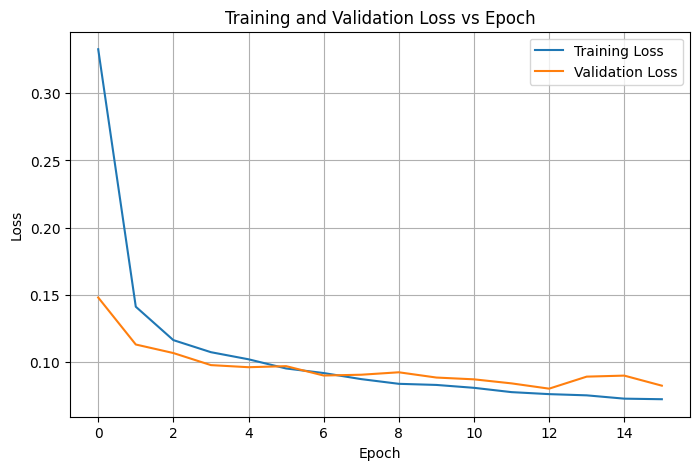

In [ ]:
#training loss and validation loss against number of epochs for observing whether the model is learning and if overfitting is occurring
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss vs Epoch")
plt.legend()
plt.grid(True)

plt.show()

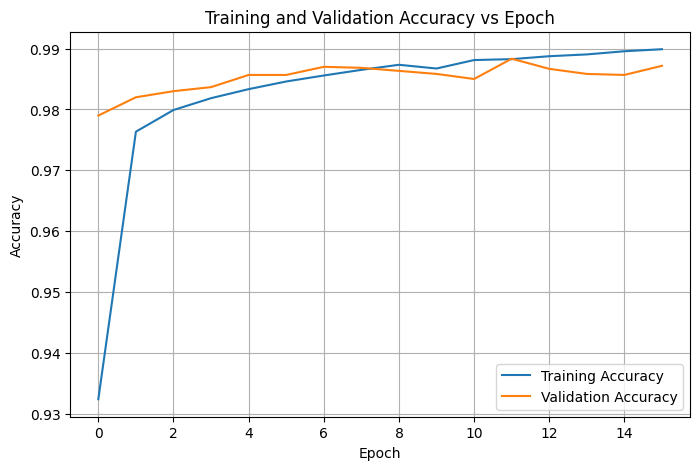

In [ ]:
#training and validation accuracy against epochs to evaluate learning and generalization
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy vs Epoch")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
#final trained model on unseen test data
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.06930123269557953
Test Accuracy: 0.9907000064849854


In [ ]:
#propbability predictio for every test image
y_probability = model.predict(X_test)
#convert probability prediction into predicted digit class
y_pred = np.argmax(
    y_probability,
    axis=1
)

print("First 20 Predictions:")
print(y_pred[:20])

print("\nFirst 20 Actual Labels:")
print(y_test[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
First 20 Predictions:
[7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]

First 20 Actual Labels:
[7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


In [ ]:
#calculating accuracy,prediction,recall and f1 score to evaluate the performance of model
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

Accuracy : 0.9907
Precision: 0.9907610668352105
Recall   : 0.9907
F1-Score : 0.9907052532949369


In [ ]:
#
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       1.00      1.00      1.00      1135
           2       0.98      1.00      0.99      1032
           3       0.99      0.99      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.97      0.99      0.98       892
           6       1.00      0.98      0.99       958
           7       0.99      0.98      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.98      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



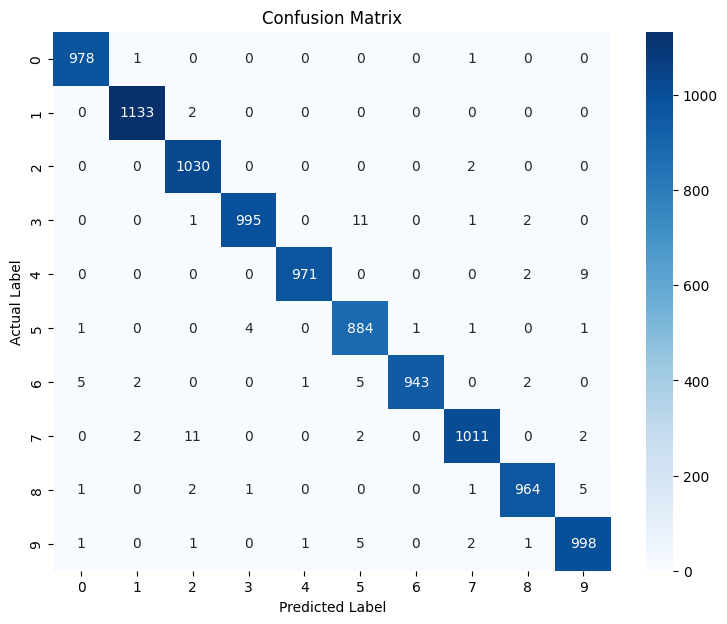

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
final_train_accuracy = history.history["accuracy"][-1]
final_val_accuracy = history.history["val_accuracy"][-1]

print("Final Training Accuracy  :", final_train_accuracy)
print("Final Validation Accuracy:", final_val_accuracy)

accuracy_gap = final_train_accuracy - final_val_accuracy

print("Training-Validation Gap  :", accuracy_gap)

Final Training Accuracy  : 0.9898889064788818
Final Validation Accuracy: 0.9871666431427002
Training-Validation Gap  : 0.0027222633361816406


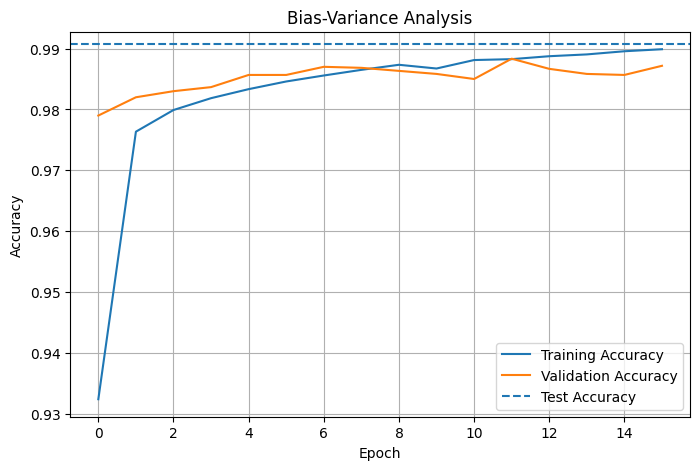

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.axhline(
    y=test_accuracy,
    linestyle="--",
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Bias-Variance Analysis")
plt.legend()
plt.grid(True)

plt.show()

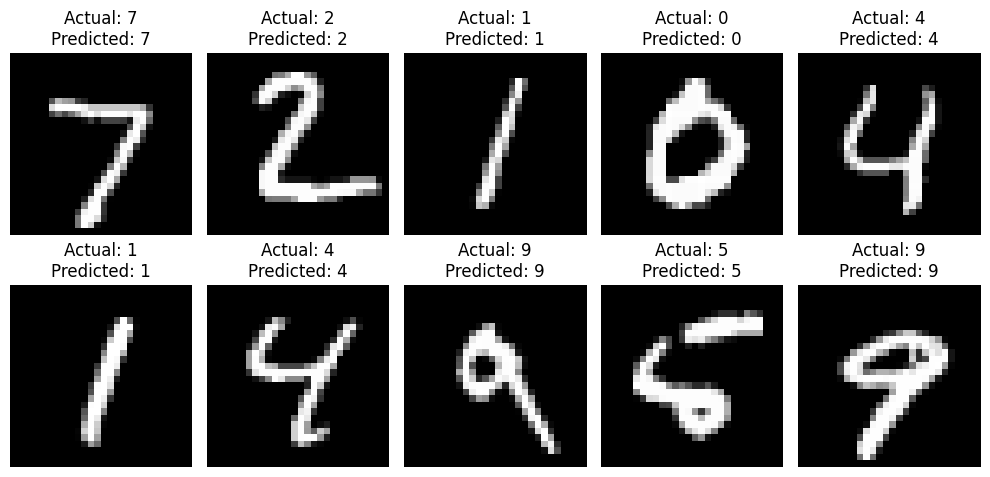

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[i]}\n"
        f"Predicted: {y_pred[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
incorrect_indices = np.where(
    y_pred != y_test
)[0]

print(
    "Number of incorrect predictions:",
    len(incorrect_indices)
)

Number of incorrect predictions: 93


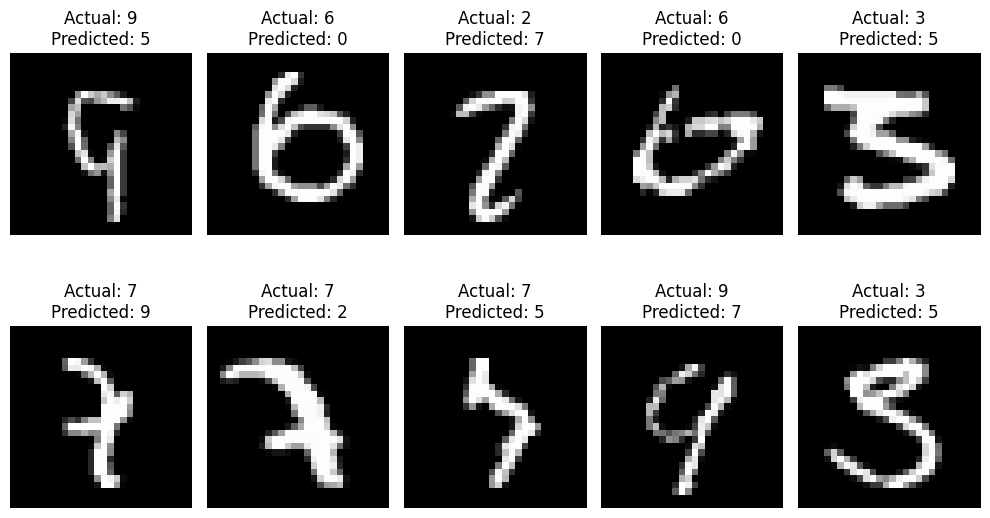

In [ ]:
plt.figure(figsize=(10, 6))

for i in range(min(10, len(incorrect_indices))):

    index = incorrect_indices[i]

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[index].reshape(28, 28),
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[index]}\n"
        f"Predicted: {y_pred[index]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Use a smaller subset for cross-validation
cv_size = 15000

X_cv = X_train[:cv_size]
y_cv = y_train[:cv_size]

print("Cross-validation dataset:", X_cv.shape)

Cross-validation dataset: (15000, 28, 28, 1)


In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = []

for fold, (train_index, val_index) in enumerate(
    skf.split(X_cv, y_cv),
    start=1
):

    print(f"\nTraining Fold {fold}")

    X_fold_train = X_cv[train_index]
    X_fold_val = X_cv[val_index]

    y_fold_train = y_cv[train_index]
    y_fold_val = y_cv[val_index]

    cv_model = build_model()

    cv_model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    cv_model.fit(
        X_fold_train,
        y_fold_train,
        epochs=3,
        batch_size=64,
        validation_data=(X_fold_val, y_fold_val),
        verbose=0
    )

    _, fold_accuracy = cv_model.evaluate(
        X_fold_val,
        y_fold_val,
        verbose=0
    )

    cv_scores.append(fold_accuracy)

    print(
        f"Fold {fold} Accuracy: "
        f"{fold_accuracy:.4f}"
    )

print("\nCross-Validation Scores:")
print(cv_scores)

print(
    "\nMean Cross-Validation Accuracy:",
    np.mean(cv_scores)
)


Training Fold 1
Fold 1 Accuracy: 0.9720

Training Fold 2
Fold 2 Accuracy: 0.9763

Training Fold 3
Fold 3 Accuracy: 0.9653

Training Fold 4
Fold 4 Accuracy: 0.9763

Training Fold 5
Fold 5 Accuracy: 0.9727

Cross-Validation Scores:
[0.972000002861023, 0.9763333201408386, 0.9653333425521851, 0.9763333201408386, 0.9726666808128357]

Mean Cross-Validation Accuracy: 0.9725333333015442


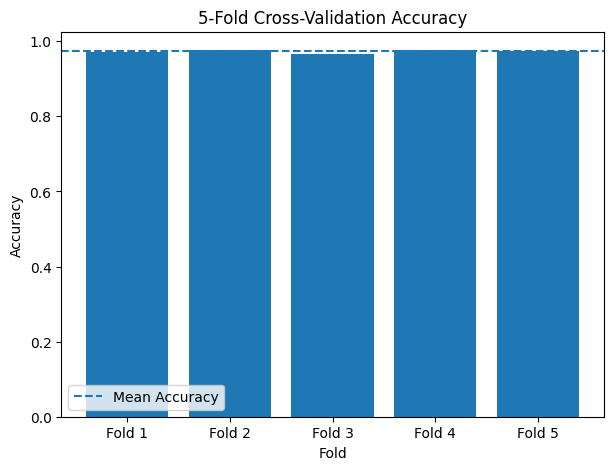

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"],
    cv_scores
)

plt.axhline(
    np.mean(cv_scores),
    linestyle="--",
    label="Mean Accuracy"
)

plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("5-Fold Cross-Validation Accuracy")
plt.legend()

plt.show()

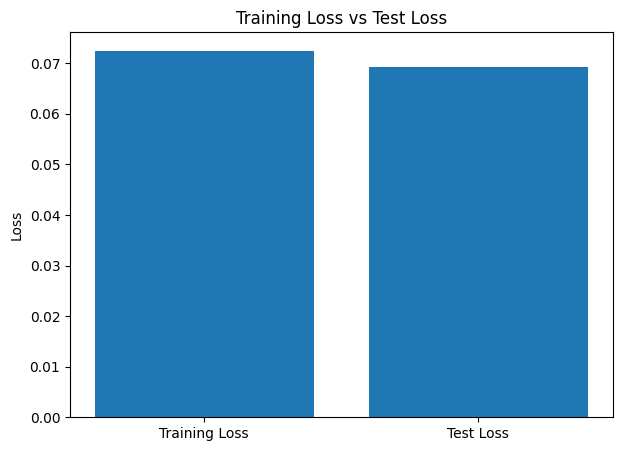

Final Training Loss: 0.07249560952186584
Test Loss: 0.06930123269557953


In [ ]:
final_train_loss = history.history["loss"][-1]

loss_values = [
    final_train_loss,
    test_loss
]

labels = [
    "Training Loss",
    "Test Loss"
]

plt.figure(figsize=(7, 5))

plt.bar(
    labels,
    loss_values
)

plt.ylabel("Loss")
plt.title("Training Loss vs Test Loss")

plt.show()

print("Final Training Loss:", final_train_loss)
print("Test Loss:", test_loss)

In [ ]:
print("=" * 45)
print("FINAL MODEL RESULTS")
print("=" * 45)

print(f"Test Accuracy  : {accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"F1-Score       : {f1:.4f}")
print(f"Test Loss      : {test_loss:.4f}")

print("=" * 45)

print(
    f"Mean CV Accuracy: "
    f"{np.mean(cv_scores):.4f}"
)

print(
    f"Number of Epochs Trained: "
    f"{len(history.history['loss'])}"
)

FINAL MODEL RESULTS
Test Accuracy  : 0.9907
Precision      : 0.9908
Recall         : 0.9907
F1-Score       : 0.9907
Test Loss      : 0.0693
Mean CV Accuracy: 0.9725
Number of Epochs Trained: 16


In [ ]:
model.save(
    "MNIST_CNN_L2_Dropout.keras"
)

print("Model saved successfully!")

Model saved successfully!
